## Preparations for Google Colab

In [1]:
# needed packages
#!pip install -q RDKit pyarrow>=13.0.0
#pip3 install pandas==3.0.3
#!pip install lifelines

#from google.colab import drive
#drive.mount('/content/drive', force_remount=True)

## Preparation

In [2]:
%pip install torch-geometric


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import torch.nn as nn
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error, silhouette_score
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr, spearmanr
#from lifelines.utils import concordance_index
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import pandas as pd
import pickle
import sys
import math
import random
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
import seaborn as sns
from rdkit import Chem
from torch_geometric.data import Data
import sys
sys.path.append('/content/drive/MyDrive')
from gnn_models_utils import (
    DrugResponseDataset,
    EarlyStopping,
    build_pyg_dataset,
    smiles_to_graph,
    weighted_mse_loss,
    set_seed,
    GroundedCrossAttentionModel,
    GCNDrugEncoder,
    #GATDrugEncoder,
    #GINDrugEncoder
)
from tqdm.auto import tqdm
import os
from pathlib import Path
molclr_path = os.path.abspath('../MolCLR')
if molclr_path not in sys.path:
    sys.path.append(molclr_path)
from models.gcn_molclr import GCN

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
import pandas as pd
df = pd.read_parquet("/Users/lukasrasche/Downloads/harmonized_data_2292026_rightSMILES.parquet")
print(f"Data set successfully loaded: {df.shape}")

Data set successfully loaded: (144082, 2024)


In [5]:
#df.to_parquet("/content/drive/MyDrive/datasets/harmonized_data_2292026_rightSMILES.parquet")

## Check dataset

In [6]:
'''import re
other_cols = [
    col for col in df.columns
    if not col.startswith('Bit_') and not re.match(r'.* \(\d+\)', col)
]

print(f"Columns found ({len(other_cols)}):")
for col in other_cols:
    print(col)'''

<>:4: SyntaxWarning: invalid escape sequence '\('
<>:4: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_98433/1353852994.py:4: SyntaxWarning: invalid escape sequence '\('
  if not col.startswith('Bit_') and not re.match(r'.* \(\d+\)', col)


'import re\nother_cols = [\n    col for col in df.columns\n    if not col.startswith(\'Bit_\') and not re.match(r\'.* \\(\\d+\\)\', col)\n]\n\nprint(f"Columns found ({len(other_cols)}):")\nfor col in other_cols:\n    print(col)'

In [7]:
# Check the sample for known active ingredients
'''test_drugs = ['Paclitaxel', 'Cisplatin', 'Doxorubicin', 'Gefitinib']
check_df = df[df['DRUG_NAME'].isin(test_drugs)][['DRUG_ID', 'DRUG_NAME', 'SMILES']].drop_duplicates()
print(check_df)'''

"test_drugs = ['Paclitaxel', 'Cisplatin', 'Doxorubicin', 'Gefitinib']\ncheck_df = df[df['DRUG_NAME'].isin(test_drugs)][['DRUG_ID', 'DRUG_NAME', 'SMILES']].drop_duplicates()\nprint(check_df)"

In [8]:
'''print(df['CANCER_TYPE'].unique())'''

"print(df['CANCER_TYPE'].unique())"

## Training data

In [9]:
'''# training data group split in train val
target = 'LN_IC50'
pharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe', 'PosIonizable', 'NegIonizable', 'ZnBinder']
mfp_cols = [col for col in df.columns if col.startswith('Bit_')]
X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')
X_chem = df[pharmacophores + mfp_cols]
y = df[target].values.astype('float32')

# split data into train and test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=6726)
idx_train_val, idx_test = next(gss_test.split(X_genomic, y, groups=df['DRUG_ID']))

# separate validation set from training set
groups_train_val = df['DRUG_ID'].iloc[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=42)
idx_train, idx_val = next(gss_val.split(X_genomic[idx_train_val], y[idx_train_val], groups=groups_train_val))

idx_train = idx_train_val[idx_train]
idx_val = idx_train_val[idx_val]

preprocessor = ColumnTransformer(
    transformers=[
        ('pharmacophore', StandardScaler(), pharmacophores),
        #('mfp', PCA(n_components=50, random_state=42), mfp_cols)
        ('mfp', 'passthrough', mfp_cols)
    ],
    remainder='drop'
)
gene_scaler = StandardScaler()

X_genomic_train = gene_scaler.fit_transform(X_genomic[idx_train])
X_chem_train = preprocessor.fit_transform(X_chem.iloc[idx_train])

X_genomic_val = gene_scaler.transform(X_genomic[idx_val])
X_chem_val = preprocessor.transform(X_chem.iloc[idx_val])

X_genomic_test = gene_scaler.transform(X_genomic[idx_test])
X_chem_test = preprocessor.transform(X_chem.iloc[idx_test])

# scale IC50 values
#scaler = StandardScaler()
y_train = y[idx_train]#scaler.fit_transform(y[idx_train].reshape(-1, 1)).flatten()
y_val = y[idx_val]#scaler.transform(y[idx_val].reshape(-1, 1)).flatten()
y_test = y[idx_test]#scaler.transform(y[idx_test].reshape(-1, 1)).flatten()'''

<>:5: SyntaxWarning: invalid escape sequence '\('
<>:5: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_98433/1538051907.py:5: SyntaxWarning: invalid escape sequence '\('
  X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')


"# training data group split in train val\ntarget = 'LN_IC50'\npharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe', 'PosIonizable', 'NegIonizable', 'ZnBinder']\nmfp_cols = [col for col in df.columns if col.startswith('Bit_')]\nX_genomic = df.filter(regex=r'.* \\(.*\\)').values.astype('float32')\nX_chem = df[pharmacophores + mfp_cols]\ny = df[target].values.astype('float32')\n\n# split data into train and test\ngss_test = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=6726)\nidx_train_val, idx_test = next(gss_test.split(X_genomic, y, groups=df['DRUG_ID']))\n\n# separate validation set from training set\ngroups_train_val = df['DRUG_ID'].iloc[idx_train_val]\ngss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=42)\nidx_train, idx_val = next(gss_val.split(X_genomic[idx_train_val], y[idx_train_val], groups=groups_train_val))\n\nidx_train = idx_train_val[idx_train]\nidx_val = idx_train_val[idx_val]\n\npreprocessor = ColumnTransformer

In [10]:
'''def make_loaders(batch_size=128, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        DrugResponseDataset(X_genomic_train, X_chem_train, y_train),
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
        generator=g,
    )
    val_loader = DataLoader(
        DrugResponseDataset(X_genomic_val, X_chem_val, y_val),
        batch_size=batch_size,
        shuffle=False,
    )
    test_loader = DataLoader(
        DrugResponseDataset(X_genomic_test, X_chem_test, y_test),
        batch_size=batch_size,
        shuffle=False,
    )
    return train_loader, val_loader, test_loader

class DrugResponseDataset(Dataset):
    def __init__(self, X_gen, X_ch, labels):
        self.X_genomic = torch.tensor(X_gen, dtype=torch.float32)
        self.X_chem = torch.tensor(X_ch if isinstance(X_ch, np.ndarray) else X_ch.values, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_genomic[idx], self.X_chem[idx], self.y[idx]'''

'def make_loaders(batch_size=128, seed=42):\n    torch.manual_seed(seed)\n    np.random.seed(seed)\n    random.seed(seed)\n\n    g = torch.Generator()\n    g.manual_seed(seed)\n\n    train_loader = DataLoader(\n        DrugResponseDataset(X_genomic_train, X_chem_train, y_train),\n        batch_size=batch_size,\n        shuffle=True,\n        drop_last=True,\n        generator=g,\n    )\n    val_loader = DataLoader(\n        DrugResponseDataset(X_genomic_val, X_chem_val, y_val),\n        batch_size=batch_size,\n        shuffle=False,\n    )\n    test_loader = DataLoader(\n        DrugResponseDataset(X_genomic_test, X_chem_test, y_test),\n        batch_size=batch_size,\n        shuffle=False,\n    )\n    return train_loader, val_loader, test_loader\n\nclass DrugResponseDataset(Dataset):\n    def __init__(self, X_gen, X_ch, labels):\n        self.X_genomic = torch.tensor(X_gen, dtype=torch.float32)\n        self.X_chem = torch.tensor(X_ch if isinstance(X_ch, np.ndarray) else X_ch.values, 

## Different ways to cluster genes

### Pairwise correlation, then hierarchical clustering, fixed amount of clusters!

In [11]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

gene_feature_names = df.filter(regex=r'.* \(.*\)').columns.tolist()

# correlation matrix for genomic features
X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')
gene_corr = np.corrcoef(X_genomic.T)  # (978, 978)

# distance matrix and ward-linkage
dist_matrix = np.clip(1.0 - gene_corr, 0, 2)
np.fill_diagonal(dist_matrix, 0)
condensed_dist = pdist(dist_matrix)
linkage_matrix = linkage(condensed_dist, method='ward')

# cut into X clusters (tokens)
num_tokens = 32
gene_clusters = fcluster(linkage_matrix, t=num_tokens, criterion='maxclust') - 1

gene_token_indices = [np.where(gene_clusters == i)[0] for i in range(num_tokens)]

for i, indices in enumerate(gene_token_indices):
    print(f"Gene Token {i}: {len(indices)} genes assigned")

Gene Token 0: 46 genes assigned
Gene Token 1: 65 genes assigned
Gene Token 2: 13 genes assigned
Gene Token 3: 28 genes assigned
Gene Token 4: 18 genes assigned
Gene Token 5: 43 genes assigned
Gene Token 6: 38 genes assigned
Gene Token 7: 26 genes assigned
Gene Token 8: 48 genes assigned
Gene Token 9: 20 genes assigned
Gene Token 10: 40 genes assigned
Gene Token 11: 14 genes assigned
Gene Token 12: 11 genes assigned
Gene Token 13: 46 genes assigned
Gene Token 14: 48 genes assigned
Gene Token 15: 26 genes assigned
Gene Token 16: 25 genes assigned
Gene Token 17: 39 genes assigned
Gene Token 18: 21 genes assigned
Gene Token 19: 39 genes assigned
Gene Token 20: 36 genes assigned
Gene Token 21: 12 genes assigned
Gene Token 22: 11 genes assigned
Gene Token 23: 24 genes assigned
Gene Token 24: 34 genes assigned
Gene Token 25: 26 genes assigned
Gene Token 26: 31 genes assigned
Gene Token 27: 16 genes assigned
Gene Token 28: 40 genes assigned
Gene Token 29: 38 genes assigned
Gene Token 30: 31 ge

In [ ]:
cluster_sizes = np.bincount(gene_clusters, minlength=num_tokens)
print(
    f"Cluster: {len(cluster_sizes)}, "
    f"Größe min/median/max: "
    f"{cluster_sizes.min()}/{np.median(cluster_sizes):.0f}/{cluster_sizes.max()}"
)
print("Größen:", cluster_sizes.tolist())

### Cancer type
Each gene is assigned to the cancer type token for which it exhibits the highest specific upregulation (maximum Z-score) compared to all other cancer types.

In [12]:
'''
gene_cols = df.filter(regex=r'.* \(.*\)').columns.tolist()
X_genes = df[gene_cols].values
cancer_types = df['CANCER_TYPE'].values
unique_cancer_types = df['CANCER_TYPE'].unique()

mean_expr = np.array([X_genes[cancer_types == ct].mean(axis=0) for ct in unique_cancer_types])
mean_expr_z = (mean_expr - mean_expr.mean(axis=0)) / (mean_expr.std(axis=0) + 1e-8)
gene_assignments = np.argmax(mean_expr_z, axis=0)

gene_token_indices = []
active_labels = []

for ct_idx, ct_name in enumerate(unique_cancer_types):
    idx = np.where(gene_assignments == ct_idx)[0]
    if len(idx) > 0:
        gene_token_indices.append(idx)
        active_labels.append(ct_name)
        print(f"Token {len(gene_token_indices)-1} ({ct_name}): {len(idx)} genes")
'''

<>:2: SyntaxWarning: invalid escape sequence '\('
<>:2: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_98433/349639104.py:2: SyntaxWarning: invalid escape sequence '\('
  gene_cols = df.filter(regex=r'.* \(.*\)').columns.tolist()


'\ngene_cols = df.filter(regex=r\'.* \\(.*\\)\').columns.tolist()\nX_genes = df[gene_cols].values\ncancer_types = df[\'CANCER_TYPE\'].values\nunique_cancer_types = df[\'CANCER_TYPE\'].unique()\n\nmean_expr = np.array([X_genes[cancer_types == ct].mean(axis=0) for ct in unique_cancer_types])\nmean_expr_z = (mean_expr - mean_expr.mean(axis=0)) / (mean_expr.std(axis=0) + 1e-8)\ngene_assignments = np.argmax(mean_expr_z, axis=0)\n\ngene_token_indices = []\nactive_labels = []\n\nfor ct_idx, ct_name in enumerate(unique_cancer_types):\n    idx = np.where(gene_assignments == ct_idx)[0]\n    if len(idx) > 0:\n        gene_token_indices.append(idx)\n        active_labels.append(ct_name)\n        print(f"Token {len(gene_token_indices)-1} ({ct_name}): {len(idx)} genes")\n'

### WGCNA

In [13]:
'''import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# pearson correlation
corr_matrix = np.corrcoef(X_genomic.T)

# Soft Thresholding (Create Adjacency Matrix)
# beta=6 is the standard bioinformatics value, to suppress weak noise and highlight strong signaling pathways.
beta = 6
adj_matrix = np.abs(corr_matrix) ** beta

# Calculate the Topological Overlap Measure (TOM)
# Matrix multiplication identifies the shared neighborhoods (signal pathways)
l_matrix = np.dot(adj_matrix, adj_matrix)

# Sum of connection strengths per gene (Connectivity)
k = np.sum(adj_matrix, axis=1)
k_min_matrix = np.minimum.outer(k, k)

# WGCNA TOM Formula
tom_matrix = (l_matrix + adj_matrix) / (k_min_matrix + 1.0 - adj_matrix)
np.fill_diagonal(tom_matrix, 1.0)

# Convert to a dissimilarity matrix
dist_matrix = 1.0 - tom_matrix
# Handle rounding errors and set the diagonal to 0
dist_matrix = np.clip(dist_matrix, 0.0, 1.0)
np.fill_diagonal(dist_matrix, 0.0)

# Hierarchical Clustering
condensed_dist = squareform(dist_matrix, checks=False)
Z = linkage(condensed_dist, method='average')

candidate_k = range(2, 51)
scores = []
for k in candidate_k:
    labels = fcluster(Z, t=k, criterion='maxclust') - 1
    # Silhouette score based on the WGCNA distance matrix
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    scores.append(score)

optimal_k = candidate_k[np.argmax(scores)]
print(f"Optimal number of tokens found: {optimal_k} (Silhouette Score: {max(scores):.4f})")

gene_clusters = fcluster(Z, t=optimal_k, criterion='maxclust') - 1
gene_token_indices = [np.where(gene_clusters == i)[0] for i in range(optimal_k)]

for i, indices in enumerate(gene_token_indices):
    print(f"Gene Token {i} (WGCNA module): {len(indices)} genes assigned")
'''

'import numpy as np\nfrom scipy.cluster.hierarchy import linkage, fcluster\nfrom scipy.spatial.distance import squareform\n\n# pearson correlation\ncorr_matrix = np.corrcoef(X_genomic.T)\n\n# Soft Thresholding (Create Adjacency Matrix)\n# beta=6 is the standard bioinformatics value, to suppress weak noise and highlight strong signaling pathways.\nbeta = 6\nadj_matrix = np.abs(corr_matrix) ** beta\n\n# Calculate the Topological Overlap Measure (TOM)\n# Matrix multiplication identifies the shared neighborhoods (signal pathways)\nl_matrix = np.dot(adj_matrix, adj_matrix)\n\n# Sum of connection strengths per gene (Connectivity)\nk = np.sum(adj_matrix, axis=1)\nk_min_matrix = np.minimum.outer(k, k)\n\n# WGCNA TOM Formula\ntom_matrix = (l_matrix + adj_matrix) / (k_min_matrix + 1.0 - adj_matrix)\nnp.fill_diagonal(tom_matrix, 1.0)\n\n# Convert to a dissimilarity matrix\ndist_matrix = 1.0 - tom_matrix\n# Handle rounding errors and set the diagonal to 0\ndist_matrix = np.clip(dist_matrix, 0.0, 1

## Configuration and training for tabular fingerprints (drugs)

First creation of drug tokens

In [14]:
'''import numpy as np
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

# Select chemical columns
chem_cols = pharmacophores + mfp_cols

# Extract unique drug feature matrix
unique_drugs_df = df.drop_duplicates(subset=['DRUG_ID'])[chem_cols]
chem_values = unique_drugs_df.values.astype(np.float64)  # shape: (n_drugs, 1032)

# Compute Pearson correlation with variance check
# Identify constant columns (zero variance)
std_devs = np.std(chem_values, axis=0)
valid_mask = std_devs > 1e-8

# Compute correlation matrix
chem_corr = np.zeros((len(chem_cols), len(chem_cols)), dtype=np.float64)

# Correlate non-constant features
chem_corr_valid = np.corrcoef(chem_values[:, valid_mask].T)

# Place valid correlations into full matrix
valid_indices = np.where(valid_mask)[0]
for i_idx, i in enumerate(valid_indices):
    for j_idx, j in enumerate(valid_indices):
        chem_corr[i, j] = chem_corr_valid[i_idx, j_idx]

# Convert correlation to distance: dist = 1 - r
dist_matrix_chem = 1.0 - chem_corr

# Handle any remaining NaN/Inf values by setting distance to 1.0 (uncorrelated)
dist_matrix_chem = np.nan_to_num(dist_matrix_chem, nan=1.0, posinf=1.0, neginf=1.0)
dist_matrix_chem = np.clip(dist_matrix_chem, 0.0, 2.0)
np.fill_diagonal(dist_matrix_chem, 0.0)

# Hierarchical clustering on condensed distance matrix
condensed_dist = pdist(dist_matrix_chem)
linkage_chem = linkage(condensed_dist, method='ward')

# Extract cluster labels for X tokens
num_drug_tokens = 32
chem_cluster_labels = fcluster(linkage_chem, t=num_drug_tokens, criterion='maxclust') - 1

# Form index arrays for each token
chem_token_indices = [
    np.where(chem_cluster_labels == i)[0] for i in range(num_drug_tokens)
]

for i, idx in enumerate(chem_token_indices):
    print(f"Drug Token {i}: {len(idx)} features assigned")'''

'import numpy as np\nfrom scipy.cluster.hierarchy import fcluster, linkage\nfrom scipy.spatial.distance import pdist\n\n# Select chemical columns\nchem_cols = pharmacophores + mfp_cols\n\n# Extract unique drug feature matrix\nunique_drugs_df = df.drop_duplicates(subset=[\'DRUG_ID\'])[chem_cols]\nchem_values = unique_drugs_df.values.astype(np.float64)  # shape: (n_drugs, 1032)\n\n# Compute Pearson correlation with variance check\n# Identify constant columns (zero variance)\nstd_devs = np.std(chem_values, axis=0)\nvalid_mask = std_devs > 1e-8\n\n# Compute correlation matrix\nchem_corr = np.zeros((len(chem_cols), len(chem_cols)), dtype=np.float64)\n\n# Correlate non-constant features\nchem_corr_valid = np.corrcoef(chem_values[:, valid_mask].T)\n\n# Place valid correlations into full matrix\nvalid_indices = np.where(valid_mask)[0]\nfor i_idx, i in enumerate(valid_indices):\n    for j_idx, j in enumerate(valid_indices):\n        chem_corr[i, j] = chem_corr_valid[i_idx, j_idx]\n\n# Convert c

In [15]:
'''from sklearn.preprocessing import MinMaxScaler
target = 'LN_IC50'
pharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe',
                   'PosIonizable', 'NegIonizable', 'ZnBinder']
mfp_cols = [col for col in df.columns if col.startswith('Bit_')]

X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')
X_chem_raw = df[pharmacophores + mfp_cols]
y_raw = df[target].values.astype('float32')
drug_groups = df['DRUG_ID'].values

seeds = [42, 101, 1337, 9999]
#seeds = [101]
hidden_dim = 64
dropout = 0.1
lr = 2e-4
weight_decay = 1e-3
epochs = 25
patience = 5
batch_size = 512

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Used device:", device)

# ==========================================
# Run data splits and scaling ONCE
# ==========================================
print("\nPrepare datasets and GPU tensors...")
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=18092026)
idx_train_val, idx_test = next(gss_test.split(X_genomic_raw, y_raw, groups=drug_groups))

groups_train_val = drug_groups[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=18092026)
idx_tr_rel, idx_val_rel = next(
    gss_val.split(X_genomic_raw[idx_train_val], y_raw[idx_train_val], groups=groups_train_val)
)
idx_train = idx_train_val[idx_tr_rel]
idx_val = idx_train_val[idx_val_rel]

# Feature-Skalierung
preprocessor = ColumnTransformer(
    transformers=[
        ('pharmacophore', StandardScaler(), pharmacophores),
        ('mfp', 'passthrough', mfp_cols)
    ],
    remainder='drop'
)
gene_scaler = StandardScaler()

X_gen_train = gene_scaler.fit_transform(X_genomic_raw[idx_train])
X_chem_train = preprocessor.fit_transform(X_chem_raw.iloc[idx_train])

X_gen_val = gene_scaler.transform(X_genomic_raw[idx_val])
X_chem_val = preprocessor.transform(X_chem_raw.iloc[idx_val])

X_gen_test = gene_scaler.transform(X_genomic_raw[idx_test])
X_chem_test = preprocessor.transform(X_chem_raw.iloc[idx_test])

# Target scaling to [0.05, 0.95] for a stable sigmoid output
y_scaler = MinMaxScaler(feature_range=(0.05, 0.95))
y_train_scaled = y_scaler.fit_transform(y_raw[idx_train].reshape(-1, 1)).flatten().astype('float32')
y_val_scaled   = y_scaler.transform(y_raw[idx_val].reshape(-1, 1)).flatten().astype('float32')
y_test_orig    = y_raw[idx_test]

# Load data sets completely into VRAM (no more CPU transfers in the loop!)
t_X_gen_train  = torch.as_tensor(X_gen_train, dtype=torch.float32, device=device)
t_X_chem_train = torch.as_tensor(X_chem_train, dtype=torch.float32, device=device)
t_y_train      = torch.as_tensor(y_train_scaled, dtype=torch.float32, device=device)

t_X_gen_val    = torch.as_tensor(X_gen_val, dtype=torch.float32, device=device)
t_X_chem_val   = torch.as_tensor(X_chem_val, dtype=torch.float32, device=device)
t_y_val        = torch.as_tensor(y_val_scaled, dtype=torch.float32, device=device)

t_X_gen_test   = torch.as_tensor(X_gen_test, dtype=torch.float32, device=device)
t_X_chem_test  = torch.as_tensor(X_chem_test, dtype=torch.float32, device=device)

n_train = t_X_gen_train.size(0)
n_val   = t_X_gen_val.size(0)
n_test  = t_X_gen_test.size(0)
print(f"Daten im GPU-RAM: Train={n_train}, Val={n_val}, Test={n_test}")

# ==========================================
# Seed Evaluation
# ==========================================
seed_results = []
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

for run_idx, seed in enumerate(seeds):
    print(f"\n==========================================")
    print(f"Seed {run_idx + 1}/{len(seeds)} (Seed-value: {seed})")
    print(f"==========================================")

    set_seed(seed)

    model = GroundedCrossAttentionModel(
        gene_token_indices=gene_token_indices,
        chem_token_indices=chem_token_indices,
        hidden_dim=hidden_dim,
        num_heads=4,
        dropout=dropout
    ).to(device)

    criterion = nn.MSELoss()
    #criterion = weighted_mse_loss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)

    best_val_loss = float("inf")
    best_epoch = -1
    model_checkpoint_path = f"best_model_seed_{seed}.pt"

    for epoch in range(epochs):
        model.train()
        permutation = torch.randperm(n_train, device=device)
        train_loss = 0.0

        for i in range(0, n_train, batch_size):
            idx_batch = permutation[i:i + batch_size]
            b_genes = t_X_gen_train[idx_batch]
            b_chem  = t_X_chem_train[idx_batch]
            b_y     = t_y_train[idx_batch]

            optimizer.zero_grad(set_to_none=True)

            # Mixed Precision Forward Pass
            with torch.amp.autocast("cuda"):
                preds = model(b_genes, b_chem)
                loss = weighted_mse_loss(preds, b_y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * b_genes.size(0)

        # Fast Validation on the GPU
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for i in range(0, n_val, batch_size):
                b_genes = t_X_gen_val[i:i + batch_size]
                b_chem  = t_X_chem_val[i:i + batch_size]
                b_y     = t_y_val[i:i + batch_size]

                with torch.amp.autocast(device_type="cuda"):
                    preds = model(b_genes, b_chem)
                    loss = weighted_mse_loss(preds, b_y)
                val_loss += loss.item() * b_genes.size(0)

        mean_val_loss = val_loss / n_val
        scheduler.step(mean_val_loss)

        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), model_checkpoint_path)

    # Test Evaluation (with original scale for metrics)
    model.load_state_dict(torch.load(model_checkpoint_path, weights_only=True))
    model.eval()

    test_preds_list = []
    with torch.no_grad():
        for i in range(0, n_test, batch_size):
            b_genes = t_X_gen_test[i:i + batch_size]
            b_chem  = t_X_chem_test[i:i + batch_size]
            with torch.amp.autocast(device_type="cuda"):
                preds = model(b_genes, b_chem, save_attention=(i==0))
            test_preds_list.append(preds.cpu())

    # Merging and rescaling scaled predictions
    test_preds_scaled = torch.cat(test_preds_list).numpy()
    test_preds_orig = y_scaler.inverse_transform(test_preds_scaled.reshape(-1, 1)).flatten()

    test_rmse = root_mean_squared_error(y_test_orig, test_preds_orig)
    test_r2 = r2_score(y_test_orig, test_preds_orig)
    test_mae = mean_absolute_error(y_test_orig, test_preds_orig)
    test_pearson_corr, p_value_pearson = pearsonr(y_test_orig, test_preds_orig)
    test_spearman_corr, p_value_spearman = spearmanr(y_test_orig, test_preds_orig)
    #test_c_index = concordance_index(y_test_orig, test_preds_orig)

    print(f"--> Result Seed {seed}: Best Epoch: {best_epoch:02d} | Val Loss: {best_val_loss:.4f} | Test RMSE: {test_rmse:.4f} | Test R²: {test_r2:.4f}")

    seed_results.append({
        "seed": seed,
        "best_epoch": best_epoch,
        "val_loss": best_val_loss,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_mae": test_mae,
        "test_pearson_corr": test_pearson_corr,
        "test_spearman_corr": test_spearman_corr#,
        #"test_c_index": test_c_index
    })

df_results = pd.DataFrame(seed_results)
print("\n" + "="*50)
print("Analysis of all seeds")
print("="*50)
print(df_results.to_string(index=False))
print("\n--- Aggregated metrics (mean ± std) ---")
print(f"Test RMSE: {df_results['test_rmse'].mean():.4f} ± {df_results['test_rmse'].std():.4f}")
print(f"Test R²:   {df_results['test_r2'].mean():.4f} ± {df_results['test_r2'].std():.4f}")
# Spearman does not measure absolute accuracy, but rather how well the order of the predictions matches reality.
# Spearman penalizes it somewhat more severely when an active ingredient that should
# actually be in first place slips to the very bottom of the list (e.g., 100th place) than the C-index would.
print(f"Test Spearman coefficient: {df_results['test_spearman_corr'].mean():.4f} ± {df_results['test_spearman_corr'].std():.4f}")
# Pearson correlation measures the linear relationship between your predictions and the true values (from -1 to +1).
print(f"Test Pearson coefficient: {df_results['test_pearson_corr'].mean():.4f} ± {df_results['test_pearson_corr'].std():.4f}")
# CI indicates the probability that, given two random samples, the model will correctly predict which of the two reacts more sensitively.
# Specifically, a C-index of 0.70 means this: If I select any two drug-cell line
# pairs from the test set, my model correctly predicts 70% of the time which of the two pairs has the lower Z-score.
# good to understand for biologists or doctors
#print(f"Concordance index: {df_results['test_c_index'].mean():.4f} ± {df_results['test_c_index'].std():.4f}")
# more robust than RMSE
print(f"Test mean absolute error: {df_results['test_mae'].mean():.4f} ± {df_results['test_mae'].std():.4f}")
print("\n" + "="*50 + "\n")
'''

<>:7: SyntaxWarning: invalid escape sequence '\('
<>:7: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_98433/485416079.py:7: SyntaxWarning: invalid escape sequence '\('
  X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')


'from sklearn.preprocessing import MinMaxScaler\ntarget = \'LN_IC50\'\npharmacophores = [\'Donor\', \'Acceptor\', \'Aromatic\', \'Hydrophobe\', \'LumpedHydrophobe\',\n                   \'PosIonizable\', \'NegIonizable\', \'ZnBinder\']\nmfp_cols = [col for col in df.columns if col.startswith(\'Bit_\')]\n\nX_genomic_raw = df.filter(regex=r\'.* \\(.*\\)\').values.astype(\'float32\')\nX_chem_raw = df[pharmacophores + mfp_cols]\ny_raw = df[target].values.astype(\'float32\')\ndrug_groups = df[\'DRUG_ID\'].values\n\nseeds = [42, 101, 1337, 9999]\n#seeds = [101]\nhidden_dim = 64\ndropout = 0.1\nlr = 2e-4\nweight_decay = 1e-3\nepochs = 25\npatience = 5\nbatch_size = 512\n\ndevice = torch.device("cuda" if torch.cuda.is_available() else "cpu")\nprint("Used device:", device)\n\n# ==========================================\n# Run data splits and scaling ONCE\n# ==========================================\nprint("\nPrepare datasets and GPU tensors...")\ngss_test = GroupShuffleSplit(n_splits=1, test_

## Configuration for graph representations (drugs)

### Parameters and data

In [16]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold
from torch_geometric.loader import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import importlib
import gnn_models_utils

target = 'LN_IC50'
smiles_raw = df['SMILES'].values
X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')
y_raw = df[target].values.astype('float32')
drug_groups = df['DRUG_ID'].values

'''
# ==========================================
# TEMPORARY OUTLIER REMOVAL
# ==========================================
valid_mask = (y_raw >= -5.5) & (y_raw <= 7.5)
y_raw = y_raw[valid_mask]
X_genomic_raw = X_genomic_raw[valid_mask]
smiles_raw = smiles_raw[valid_mask]
drug_groups = drug_groups[valid_mask]
outliers_removed = (~valid_mask).sum()
print(f"Es wurden {outliers_removed} Ausreißer gelöscht.")
'''

'''print("Create 20% Subset for fast test-training...")
gss_subset = GroupShuffleSplit(n_splits=1, train_size=0.20, random_state=1337)
idx_subset, _ = next(gss_subset.split(X_genomic_raw, y_raw, groups=drug_groups))
smiles_raw = smiles_raw[idx_subset]
X_genomic_raw = X_genomic_raw[idx_subset]
y_raw = y_raw[idx_subset]
drug_groups = drug_groups[idx_subset]'''

#seeds = [42, 101, 1337, 9999]
seeds = [101]
hidden_dim = 64
dropout = 0.29086750620888463
lr = 2.8541928359599132e-05
weight_decay = 1e-3
epochs = 30
patience = 5
batch_size = 64
gnn_type="GCN"  # Options: "GCN", "GAT", "GIN"
freeze_bool = True  # Whether to freeze the MolCLR backbone during training
#hidden_dim': 128, 'lr': 0.00019271571819332161, 'dropout': 0.32368316014688053, 'batch_size': 256
#{'hidden_dim': 64, 'lr': 2.8541928359599132e-05, 'dropout': 0.29086750620888463, 'batch_size': 64}

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Used device:", device)
# ==========================================
# Run data splits and scaling ONCE
# ==========================================
'''
print("\nGroupShuffleSplit...")
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=18092026)
idx_train_val, idx_test = next(gss_test.split(X_genomic_raw, y_raw, groups=drug_groups))

groups_train_val = drug_groups[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=18092026)
idx_tr_rel, idx_val_rel = next(
    gss_val.split(X_genomic_raw[idx_train_val], y_raw[idx_train_val], groups=groups_train_val))
idx_train = idx_train_val[idx_tr_rel]
idx_val = idx_train_val[idx_val_rel]'''


# Calculate the average IC50 value for each drug
y_flat = np.array(y_raw).flatten()
groups_flat = np.array(drug_groups).flatten()
df_drugs = pd.DataFrame({'drug_group': groups_flat, 'LN_IC50': y_flat})
drug_means = df_drugs.groupby('drug_group')['LN_IC50'].mean().reset_index() # combines all samples of the same medication and calculates the average target value for that specific medication.
# pd.qcut to obtain 5 groups of medications of equal size
drug_means['mean_bin'] = pd.qcut(drug_means['LN_IC50'], q=5, labels=False)
# stratification only works with discrete values
skf_test = StratifiedKFold(n_splits=10, shuffle=True, random_state=18092026) # divides the individual medications into 10 groups based on their assigned class.
train_val_drug_idx, test_drug_idx = next(skf_test.split(drug_means['drug_group'], drug_means['mean_bin']))
test_drugs = drug_means.iloc[test_drug_idx]['drug_group'].values
train_val_drugs = drug_means.iloc[train_val_drug_idx]['drug_group'].values
# Create a new DataFrame containing only the remaining train/val drugs
drug_means_train_val = drug_means.iloc[train_val_drug_idx].reset_index(drop=True)
skf_val = StratifiedKFold(n_splits=9, shuffle=True, random_state=18092026)
train_drug_idx, val_drug_idx = next(skf_val.split(drug_means_train_val['drug_group'], drug_means_train_val['mean_bin']))
val_drugs = drug_means_train_val.iloc[val_drug_idx]['drug_group'].values
train_drugs = drug_means_train_val.iloc[train_drug_idx]['drug_group'].values
# Map Back to the Sample Level
test_mask = np.isin(groups_flat, test_drugs)
val_mask = np.isin(groups_flat, val_drugs)
train_mask = np.isin(groups_flat, train_drugs)
idx_test = np.where(test_mask)[0]
idx_val = np.where(val_mask)[0]
idx_train = np.where(train_mask)[0]
print(f"Samples - Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")


# Scale genes only
gene_scaler = StandardScaler()
X_gen_train = gene_scaler.fit_transform(X_genomic_raw[idx_train])
X_gen_val = gene_scaler.transform(X_genomic_raw[idx_val])
X_gen_test = gene_scaler.transform(X_genomic_raw[idx_test])

# preprocessing target values
y_raw_clipped = np.clip(y_flat, a_min=-5.5, a_max=7.5)
y_scaler = StandardScaler()
#y_scaler = MinMaxScaler()
y_train = y_raw_clipped[idx_train]
y_val = y_raw_clipped[idx_val]
y_test_orig = y_raw_clipped[idx_test]
y_train = y_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
y_val = y_scaler.transform(y_val.reshape(-1, 1)).flatten()

Used device: mps
Samples - Train: 116092 | Val: 14247 | Test: 13743


Mean Train: 2.829
Mean Val:   2.514
Mean Test:  2.459


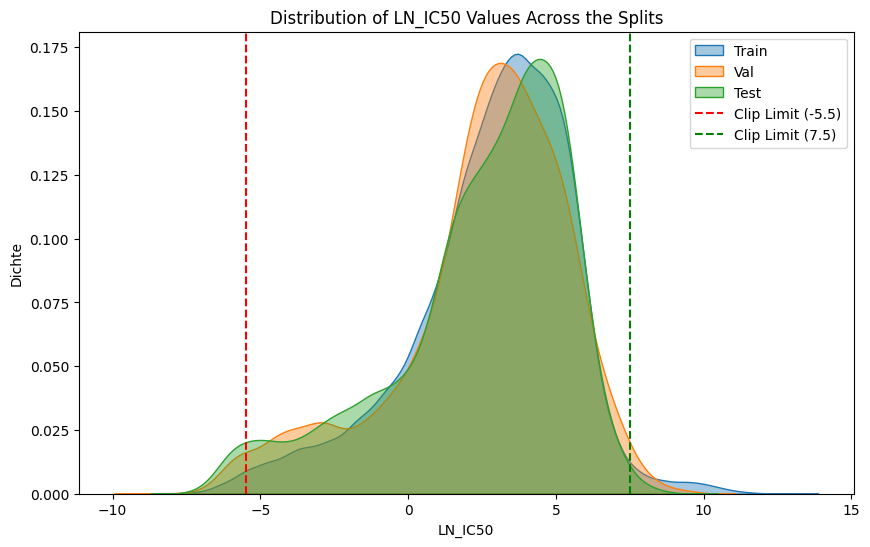

In [17]:
y_train_check = y_flat[idx_train]
y_val_check = y_flat[idx_val]
y_test_check = y_flat[idx_test]

print(f"Mean Train: {y_train_check.mean():.3f}")
print(f"Mean Val:   {y_val_check.mean():.3f}")
print(f"Mean Test:  {y_test_check.mean():.3f}")

data_to_plot = {'Train': y_train_check, 'Val': y_val_check, 'Test': y_test_check}

plt.figure(figsize=(10, 6))
for label, data in data_to_plot.items():
    sns.kdeplot(data, label=label, fill=True, alpha=0.4)
plt.axvline(x=-5.5, color='red', linestyle='--', label='Clip Limit (-5.5)')
plt.axvline(x=7.5, color='green', linestyle='--', label='Clip Limit (7.5)')
plt.title('Distribution of LN_IC50 Values Across the Splits')
plt.xlabel('LN_IC50')
plt.ylabel('Dichte')
plt.legend()
plt.show()

In [18]:
df = pd.DataFrame({'drug_group': np.array(drug_groups).flatten(),'LN_IC50': np.array(y_raw).flatten()})
drug_stats = df.groupby('drug_group')['LN_IC50'].agg(['mean', 'std', 'count', 'min', 'max']).reset_index()
drug_stats_sorted = drug_stats.sort_values(by='mean')
print("=== Medications with the lowest values ===")
print(drug_stats_sorted.head(10))
print("\n=== Medications with the highest values ===")
print(drug_stats_sorted.tail(10))

=== Medications with the lowest values ===
    drug_group      mean       std  count       min       max
156       1817 -5.196673  1.027161    554 -7.382631 -0.007070
76        1191 -4.706054  1.089799    706 -7.123910  1.838670
176       1911 -4.618691  1.838835    153 -8.574355  2.414593
197       1941 -4.095248  1.660371    706 -7.310776  2.999507
150       1811 -3.546657  1.365566    554 -7.356721  1.265955
4         1007 -3.486161  2.157966    713 -7.099015  3.088285
84        1248 -3.417683  2.646968    412 -8.391517  3.777465
96        1494 -3.377096  1.990697    705 -8.044732  4.146680
1         1004 -3.355916  2.213037    577 -7.530958  3.857855
55        1080 -3.000982  1.777715    706 -6.915668  2.966341

=== Medications with the highest values ===
    drug_group      mean       std  count       min        max
126       1620  5.408087  0.841404    659  2.606296   8.678348
233       2359  5.492749  1.137759    570  1.739554   8.714451
23        1029  5.526127  1.159916    699

### Graphs

In [19]:
import os
cache_path = '/Users/lukasrasche/Desktop/masterthesis/processed_graph_cache.pt'
bool = False
# Helper function for building PyG datasets
if bool and os.path.exists(cache_path):
    print("Load graphs from Storage...")
    graph_cache = torch.load(cache_path, weights_only=False)
else:
    unique_smiles = np.unique(smiles_raw)
    print(f"Create a graph cache for {len(unique_smiles)} unique drugs...")
    graph_cache = {}
    for smiles in unique_smiles:
        graph_cache[smiles] = smiles_to_graph(smiles)
    #torch.save(graph_cache, cache_path)
    #print("Cache saved successfully!")

print("Building PyG Graphs...")
train_dataset = build_pyg_dataset(smiles_raw[idx_train], X_gen_train, y_train, cache=graph_cache, use_cache=False) #########
val_dataset = build_pyg_dataset(smiles_raw[idx_val], X_gen_val, y_val, cache=graph_cache, use_cache=False)
test_dataset = build_pyg_dataset(smiles_raw[idx_test], X_gen_test, y_test_orig, cache=graph_cache, use_cache=False)
print(f"Graph Datasets: Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

# Create PyG DataLoaders (these automatically load the variable graphs onto the GPU at runtime)
# für Mac pin_memory=False, da sonst Fehler auftreten
g = torch.Generator()
g.manual_seed(101)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False, pin_memory=False, generator=g)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=False)

Create a graph cache for 229 unique drugs...
Building PyG Graphs...
Graph Datasets: Train=116092, Val=14247, Test=13743


### Seed evaluation

In [20]:
#seeds = [101]
# Forces the file to be re-read from memory
importlib.reload(gnn_models_utils)
from gnn_models_utils import GroundedCrossAttentionModel


Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.


EarlyStopping counter: 1 out of 15


EarlyStopping counter: 2 out of 15


EarlyStopping counter: 1 out of 15


EarlyStopping counter: 1 out of 15


EarlyStopping counter: 2 out of 15


... (9 outputs left out)

EarlyStopping counter: 12 out of 15


EarlyStopping counter: 13 out of 15


EarlyStopping counter: 14 out of 15


EarlyStopping counter: 15 out of 15
Early stopping! Training is ending.


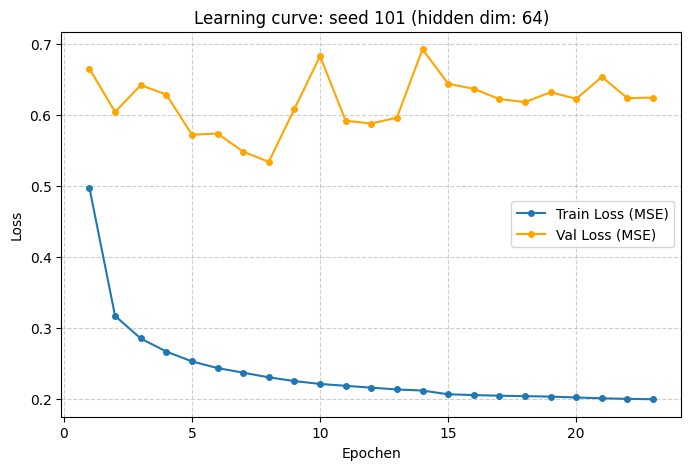

--> Result Seed 101: Best Epoch: 08 | Val Loss: 0.5337 | Test RMSE: 2.3409 | Test R²: 0.3802

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           8  0.533702   2.340916 0.380167  1.943154            0.62823            0.433264

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3409 ± nan
Test R²:   0.3802 ± nan
Test Spearman coefficient: 0.4333 ± nan
Test Pearson coefficient: 0.6282 ± nan
Test mean absolute error: 1.9432 ± nan




In [21]:
# get checkpoint path for MolCLR model
molclr_dir = Path("../MolCLR").resolve()
checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
if not checkpoint_path.is_file():
    raise FileNotFoundError(f"MolCLR checkpoint not found: {checkpoint_path}")

seed_results = []
amp_enabled = device.type in ("cuda","mps")
scaler = torch.amp.GradScaler(device.type, enabled=False)

for run_idx, seed in enumerate(seeds):
    print(f"\n==========================================")
    print(f"Seed {run_idx + 1}/{len(seeds)} (Seed-value: {seed}), GNN-Type: {gnn_type}")
    print(f"==========================================")

    set_seed(seed)
    #torch.use_deterministic_algorithms(True, warn_only=True)
    train_loader.generator.manual_seed(seed)

    molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    molclr_gcn.load_state_dict(state_dict, strict=True)

    model = GroundedCrossAttentionModel(
        gene_token_indices=gene_token_indices,
        hidden_dim=hidden_dim,
        num_heads=4,
        dropout=dropout,
        gnn_type=gnn_type,
        molclr_backbone=molclr_gcn,
        freeze_molclr=False
    ).to(device)

    #criterion = weighted_mse_loss  # custom loss function
    #criterion = nn.HuberLoss(delta=1.0) # mit RobustScaler zusammen
    criterion = nn.MSELoss()

    # differential learning rates
    if freeze_bool:
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        molclr_params = []
        other_params = []
        for name, param in model.named_parameters():
            if "drug_encoder" in name:
                molclr_params.append(param)
            else:
                other_params.append(param)
        optimizer = torch.optim.AdamW([
            {'params': molclr_params, 'lr': 1e-5},    # Tiny LR: protects chemical knowledge
            {'params': other_params, 'lr': lr}    # Normal LR: fast learning of new layers
        ], weight_decay=weight_decay)

    best_val_loss = float("inf")
    best_epoch = -1
    model_checkpoint_path = f"best_model_seed_{seed}.pt"        
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)
    early_stopping = EarlyStopping(patience=15, min_delta=0.001, path=model_checkpoint_path)

    train_loss_history = []
    val_loss_history = []

    for epoch in range(epochs):
        model.train()
        if freeze_bool:
            model.drug_encoder.eval()
        train_loss = 0.0
        # Iterating Over the PyG DataLoader
        for batch in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}", leave=False):
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=False):
                # The model receives the genes and the ENTIRE GraphBatch object
                preds = model(batch.gene, batch)
                loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Gradient Clipping
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item() * batch.num_graphs

        mean_train_loss = train_loss / len(train_dataset)

        # Fast Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                with torch.amp.autocast(device_type=device.type, enabled=False):
                    preds = model(batch.gene, batch)
                    loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                val_loss += loss.item() * batch.num_graphs

        mean_val_loss = val_loss / len(val_dataset)
        train_loss_history.append(mean_train_loss)
        val_loss_history.append(mean_val_loss)

        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), model_checkpoint_path)

        scheduler.step(mean_val_loss)
        early_stopping(mean_val_loss, model)
        if early_stopping.early_stop:
            print("Early stopping! Training is ending.")
            break

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(train_loss_history) + 1), train_loss_history, label='Train Loss (MSE)', marker='o', markersize=4)
    plt.plot(range(1, len(val_loss_history) + 1), val_loss_history, label='Val Loss (MSE)', marker='o', markersize=4, color='orange')
    plt.xlabel('Epochen')
    plt.ylabel('Loss')
    plt.title(f'Learning curve: seed {seed} (hidden dim: {hidden_dim})')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    # Test Evaluation
    model.load_state_dict(torch.load(model_checkpoint_path, weights_only=True))
    model.eval()

    test_preds_list = []
    with torch.no_grad():
        for i, batch in enumerate(test_loader):
            batch = batch.to(device)
            with torch.amp.autocast(device_type=device.type, enabled=False):
                # Attention save on the first batch
                preds = model(batch.gene, batch, save_attention=(i==0))
            test_preds_list.append(preds.cpu())

    test_preds_orig = torch.cat(test_preds_list).numpy()
    test_preds_orig = y_scaler.inverse_transform(test_preds_orig.reshape(-1, 1)).flatten()

    test_rmse = root_mean_squared_error(y_test_orig, test_preds_orig)
    test_r2 = r2_score(y_test_orig, test_preds_orig)
    test_mae = mean_absolute_error(y_test_orig, test_preds_orig)
    test_pearson_corr, p_value_pearson = pearsonr(y_test_orig, test_preds_orig)
    test_spearman_corr, p_value_spearman = spearmanr(y_test_orig, test_preds_orig)
    #test_c_index = concordance_index(y_test_orig, test_preds_orig)

    print(f"--> Result Seed {seed}: Best Epoch: {best_epoch:02d} | Val Loss: {best_val_loss:.4f} | Test RMSE: {test_rmse:.4f} | Test R²: {test_r2:.4f}")

    seed_results.append({
        "seed": seed,
        "best_epoch": best_epoch,
        "val_loss": best_val_loss,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_mae": test_mae,
        "test_pearson_corr": test_pearson_corr,
        "test_spearman_corr": test_spearman_corr#,
        #"test_c_index": test_c_index
    })

df_results = pd.DataFrame(seed_results)
print("\n" + "="*50)
print("Analysis of all seeds")
print("="*50)
print(df_results.to_string(index=False))
print("\n--- Aggregated metrics (mean ± std) ---")
print(f"Test RMSE: {df_results['test_rmse'].mean():.4f} ± {df_results['test_rmse'].std():.4f}")
print(f"Test R²:   {df_results['test_r2'].mean():.4f} ± {df_results['test_r2'].std():.4f}")
print(f"Test Spearman coefficient: {df_results['test_spearman_corr'].mean():.4f} ± {df_results['test_spearman_corr'].std():.4f}")
print(f"Test Pearson coefficient: {df_results['test_pearson_corr'].mean():.4f} ± {df_results['test_pearson_corr'].std():.4f}")
print(f"Test mean absolute error: {df_results['test_mae'].mean():.4f} ± {df_results['test_mae'].std():.4f}")
print("\n" + "="*50 + "\n")

<Figure size 800x500 with 1 Axes>

In [27]:
test_preds_orig

array([5.0333576, 4.575736 , 4.36882  , ..., 2.6032107, 3.7957258,
       2.6271238], shape=(3537,), dtype=float32)

## Optuna for automatic finetuning

In [ ]:
import optuna
import random
from torch_geometric.loader import DataLoader

sample_fraction = 1
# get checkpoint path for MolCLR model
molclr_dir = Path("../MolCLR").resolve()
checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
amp_enabled = device.type in ("cuda","mps")
scaler = torch.amp.GradScaler(device.type, enabled=False)

random.seed(101)
optuna_train_dataset = random.sample(train_dataset, int(len(train_dataset) * sample_fraction))
optuna_val_dataset = random.sample(val_dataset, int(len(val_dataset) * sample_fraction))

def objective(trial):
    # Parameter Search Space
    hidden_dim = trial.suggest_categorical("hidden_dim", [32, 64, 128])
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.2, 0.5)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])
    
    trial_train_loader = DataLoader(optuna_train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
    trial_val_loader = DataLoader(optuna_val_dataset, batch_size=batch_size, shuffle=False)

    molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    molclr_gcn.load_state_dict(state_dict, strict=True)
    model = GroundedCrossAttentionModel(
        gene_token_indices=gene_token_indices,
        hidden_dim=hidden_dim,
        num_heads=4,
        dropout=dropout,
        gnn_type="GCN",
        molclr_backbone=molclr_gcn, 
        freeze_molclr=True
    ).to(device)
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = torch.nn.MSELoss()
    
    best_val_loss = float("inf")
    
    # 15 epochs are usually more than enough for an Optuna search
    for epoch in range(15):
        model.train()
        for batch in trial_train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            
            with torch.amp.autocast(device_type=device.type, enabled=False):
                preds = model(batch.gene, batch)
                loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in trial_val_loader:
                batch = batch.to(device)
                with torch.amp.autocast(device_type=device.type, enabled=False):
                    preds = model(batch.gene, batch)
                    loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                val_loss += loss.item() * batch.num_graphs
                
        mean_val_loss = val_loss / len(optuna_val_dataset)
        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            
        # Tell Optuna what the current loss is (to cut short pointless runs early on)
        trial.report(mean_val_loss, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val_loss

# 2. Start the study
study = optuna.create_study(direction="minimize")
print(f"Start a search on {len(optuna_train_dataset)} training graphs....")

# 20 trials are enough to make a good first impression
study.optimize(objective, n_trials=20)

print("\n=== OPTUNA RESULTS ===")
print("Best Parameter:", study.best_params)
print("Best Val Loss:", study.best_value)

[I 2026-10-27 11:48:26,306] A new study created in memory with name: no-name-53277dad-dfce-4e53-aafc-b2eca31341bd


Start a search on 116092 training graphs....
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


[I 2026-10-27 12:06:40,337] Trial 0 finished with value: 1.0742049702947378 and parameters: {'hidden_dim': 64, 'lr': 0.0004965482625536168, 'dropout': 0.27296027889953056, 'weight_decay': 0.008276849013573681, 'batch_size': 256}. Best is trial 0 with value: 1.0742049702947378.


Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


[I 2026-10-27 12:47:25,371] Trial 1 finished with value: 0.9598731768543766 and parameters: {'hidden_dim': 128, 'lr': 4.129024176248623e-05, 'dropout': 0.4418886617478607, 'weight_decay': 0.009630348853703766, 'batch_size': 64}. Best is trial 1 with value: 0.9598731768543766.


Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


[I 2026-10-27 13:57:48,073] Trial 2 finished with value: 0.907371307577515 and parameters: {'hidden_dim': 64, 'lr': 0.0032019117509105824, 'dropout': 0.43965460093968217, 'weight_decay': 0.0024788522253106726, 'batch_size': 32}. Best is trial 2 with value: 0.907371307577515.


Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


In [ ]:
'''checkpoint = {
    'hyperparameters': {
        'gene_token_indices': gene_token_indices, # see creation of tokens
        'hidden_dim': hidden_dim,
        'num_heads': 4,
        'dropout': dropout,
        'gnn_type': gnn_type
    },
    'state_dict': model.state_dict()
}

file_path = f"model_{gnn_type}_gtP_seed101.pth"
torch.save(checkpoint, file_path)'''

To load model again, model class has to be present + initialise model with exact same parameters as in training

In [ ]:
'''checkpoint = torch.load("model_GAT_gtP_ohnesigmoid.pth", map_location=device, weights_only=False)
hparams = checkpoint['hyperparameters']

# **hparams automatically expands the dictionary to:
# gene_token_indices=..., hidden_dim=..., num_heads=..., dropout=...
loaded_model = GroundedCrossAttentionModel(**hparams).to(device)

loaded_model.load_state_dict(checkpoint['state_dict'])
loaded_model.eval()'''

## Residuals plot and other stuff

### Residual plot

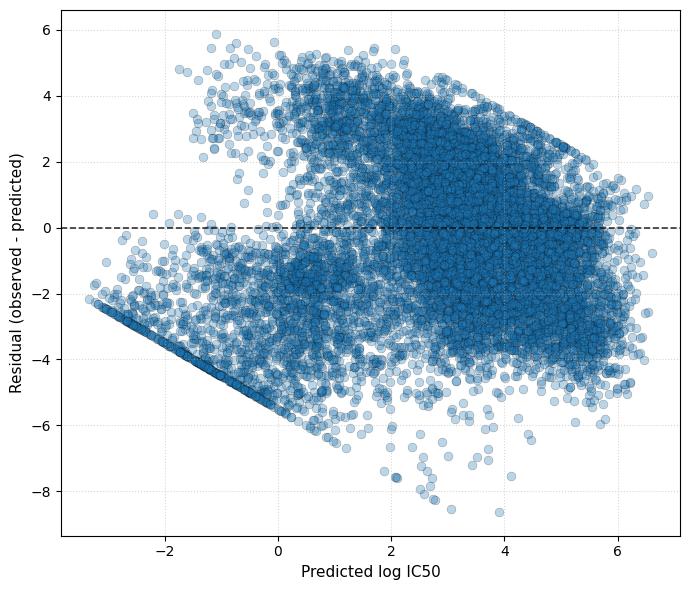

In [22]:
residuals = y_test_orig - test_preds_orig
rmse_val = root_mean_squared_error(y_test_orig, test_preds_orig)
r2_val = r2_score(y_test_orig, test_preds_orig)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(test_preds_orig, residuals, color='#1f77b4', alpha=0.3, s=40, edgecolors='black', linewidth=0.4, marker = 'o')
ax.axhline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.8)

ax.set_xlabel("Predicted log IC50", fontsize=11)
ax.set_ylabel("Residual (observed - predicted)", fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)

#info_text = (
#    f"RMSE: {rmse_val:.3f}\n"
#    f"R²: {r2_val:.3f}\n"
#)
#ax.text(0.02, 0.95, info_text, transform=ax.transAxes, fontsize=8,
#        verticalalignment='top',
#        bbox=dict(boxstyle='square,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#cccccc'))

plt.tight_layout()
#plt.savefig("residuals_vs_predicted.png", bbox_inches='tight')
plt.show()

### Other stuff

In [25]:
import pandas as pd

check_df = pd.DataFrame({
    'drug_id': drug_groups[idx_test],
    'y_true': y_test_orig,
    'y_pred': test_preds_orig,
    'residual': y_test_orig - test_preds_orig
})

# Calculate the mean residual per active ingredient
drug_summary = check_df.groupby('drug_id').agg(
    n_samples=('residual', 'count'),
    mean_residual=('residual', 'mean'),
    mean_true=('y_true', 'mean'),
    mean_pred=('y_pred', 'mean')
).sort_values('mean_residual')

print("Top 5 active ingredients with the most harmful residues:")
print(drug_summary.head(5))

Top 5 active ingredients with the most harmful residues:
         n_samples  mean_residual  mean_true  mean_pred
drug_id                                                
1191           706      -6.859329  -3.289043   3.570287
1936           706      -5.296530  -0.177886   5.118644
1809           554      -5.042986  -1.095963   3.947023
1237           712      -1.782927   0.855468   2.638395
1009           136      -1.547133   0.689731   2.236863


You can see that these outliers in residuals plot stem mainly from two/three drugs (in average)

In [26]:
extreme_drug_ids = ["1911", "1248", "1372"]
outlier_names = df[df['DRUG_ID'].isin(extreme_drug_ids)][['DRUG_ID', 'DRUG_NAME']].drop_duplicates()
print(outlier_names)

    DRUG_ID     DRUG_NAME
97     1372    Trametinib
465    1248     Daporinad
774    1911  Dactinomycin



Gene -> Drug
Shape: (32, 65)
Min: 0.0
Max: 0.06680402
Mean: 0.015384615
NaNs: 0
Sum per query (first 5): [1. 1. 1. 1. 1.]

Drug -> Gene
Shape: (65, 32)
Min: 0.02746848
Max: 0.036927983
Mean: 0.03125
NaNs: 0
Sum per query (first 5): [1. 1. 1. 1. 1.]


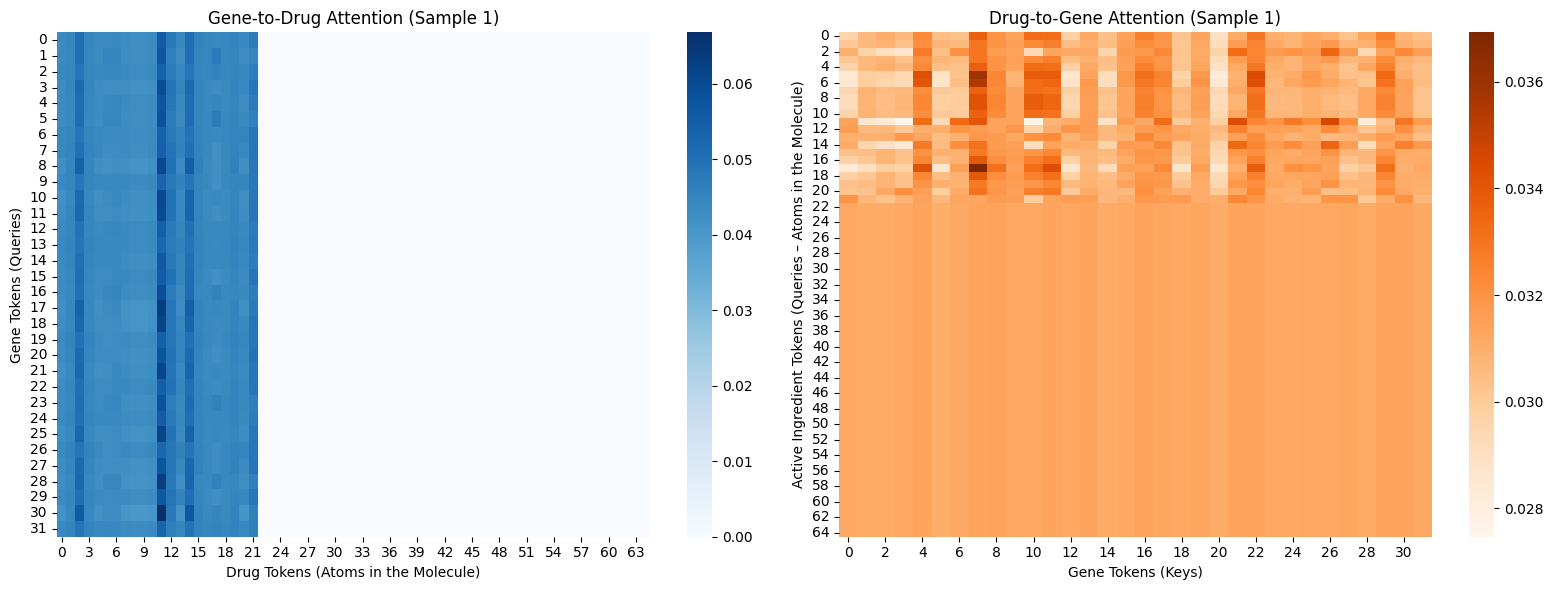

In [25]:
importlib.reload(gnn_models_utils)
from gnn_models_utils import plot_attention_weights

plot_attention_weights(model, test_loader, device, sample_idx=1)

In [ ]:
from rdkit.Chem import Draw

# Reload the PyG batch object to check the SMILES strings and names
batch = next(iter(test_loader))

num_real_atoms = batch.ptr[512] - batch.ptr[511]
print(f"The molecule in Sample 0 has exactly {num_real_atoms.item()} atoms.")

smiles_of_sample_0 = smiles_raw[idx_test][511]
mol = Chem.MolFromSmiles(smiles_of_sample_0)
print(f"SMILES: {smiles_of_sample_0}")

img = Draw.MolToImage(mol)
display(img)

In [ ]:
import numpy as np
import matplotlib
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display
from gpu.gnn_models_utils import visualize_atom_attention

# ==========================================
# Execution using the data from Sample X
# ==========================================
# We fetch the first batch from the test_loader to get the actual number of atoms
sample = 512
batch = next(iter(test_loader))
num_real_atoms_sample = (batch.ptr[sample] - batch.ptr[sample-1]).item()
smiles_sample = smiles_raw[idx_test][sample-1]

# Retrieve attention weights directly from the model (for the sample)
attn_dict = model.last_attn_weights
gene_to_drug_attn = attn_dict["gene_to_drug"][sample-1]

print(f"Visualizing Attention for SMILES: {smiles_sample}")
print(f"Number of atoms: {num_real_atoms_sample}")
visualize_atom_attention(smiles_sample, gene_to_drug_attn, num_real_atoms_sample)

Gene-to-drug:
- Attention hardly varies among the different gene tokens (rows), but instead exhibits a vertical striped pattern.
- seems like the model always prioritizes the same chemical features, regardless of the genomic profile.

Drug-to-gene:
- focus on token 1 and 3
- The values fall within a very narrow range between 0.1 and 0.15, and are thus close to the uniform distribution of 0.125

/Users/lukasrasche/Desktop/masterthesis/gpu/gnn_models_utils.py:336: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast(device_type="cuda"):


Samples analyzed in the test set: 2814
Moderate correlation between samples: 0.2281
Number of gene tokens: 22
Maximum standard deviation (gene-to-drug): 0.3236


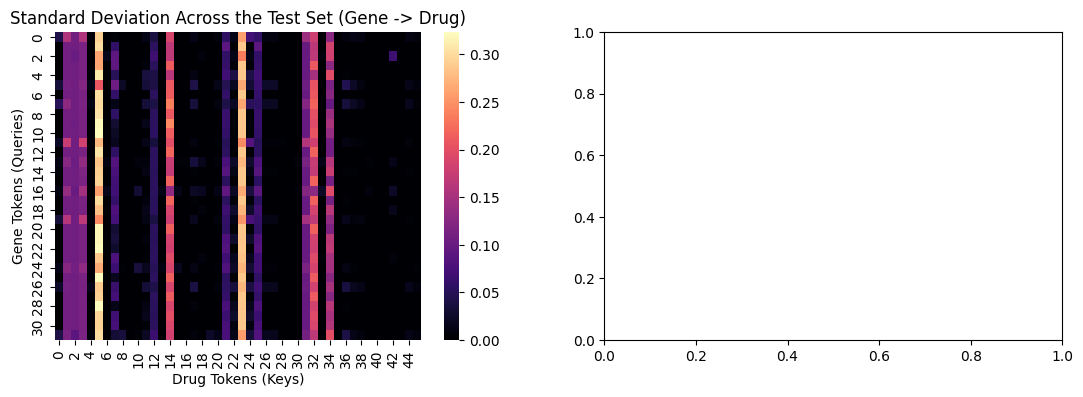

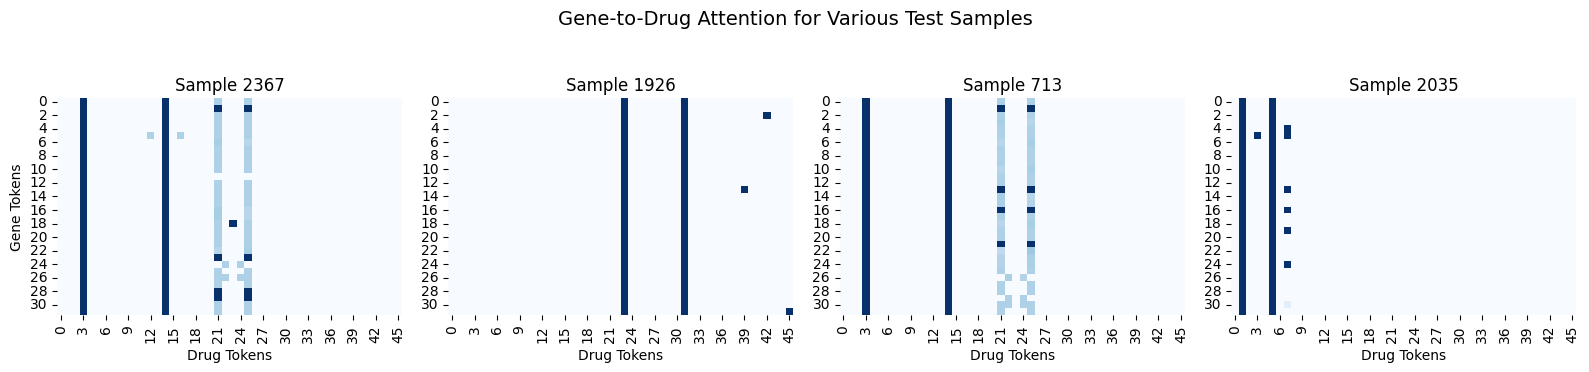

In [ ]:
importlib.reload(gnn_models_utils)
from gnn_models_utils import evaluate_attention_diversity

evaluate_attention_diversity(model, test_loader, device)

-> attention collapse would mean correlation~1 and standard deviation~0 \
so no attention collapse \
drug-to-gene shows homogeneity, means model couldn't use drug for more information about genes

## Overlap between drugs with structural similarity (global) and functional groups (local)

A. 2D Density & Correlation Analysis (Scatter / Hexbin Plot): Plot $S_{\text{struct}}$ on the X-axis and $S_{\text{FG}}$ on the Y-axis for all active ingredient pairs. Since there are $N \times (N-1) / 2$ pairs, use a hexbin or KDE plot: Calculate the Spearman rank correlation $r_s$ between the two matrices (or perform a Mantel test).

B. Quadrant Analysis (Identification of Scaffold Hops) Set thresholds (e.g., $S_{\text{struct}} \ge 0{,}5$ and $S_{\text{FG}} \ge 0{,}7$) and divide the pairs into four quadrants: High Structure + High FG: Classic chemical analogs/series. Low Structure + High FG (Scaffold Hops): Compounds with completely different scaffolds but identical functional groups. Particularly biologically relevant for your master’s thesis, as they often bind to similar targets. High Structure + Low FG: Structurally related molecules in which key groups have been substituted (potential activity cliffs).

C. $k$-NN Jaccard Overlap (Local Neighborhoods) Determine the top $k$ most similar partners for each molecule based on structure ($N_{\text{struct}}^{(k)}$) and based on functional groups ($N_{\text{FG}}^{(k)}$). $$\text{Overlap}(m) = \frac{\vert{}N_{\text{struct}}^{(k)}(m) \cap N_{\text{FG}}^{(k)}(m)\vert{}}{\vert{}N_{\text{struct}}^{(k)} (m) \cup N_{\text{FG}}^{(k)}(m)\vert{}}$$A low average overlap indicates that functional groups span different similarity spaces than 2D fingerprints.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Fragments

# Load SMILES and unique molecules
unique_drugs = df.drop_duplicates(subset=['DRUG_ID']).copy()
smiles_list = unique_drugs['SMILES'].tolist()
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

# Calculate structural similarity (Morgan Fingerprints -> Tanimoto)
fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024) for m in mols]
n_mols = len(mols)

struct_sim_matrix = np.zeros((n_mols, n_mols))
for i in range(n_mols):
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps)
    struct_sim_matrix[i] = sims

# Calculate the similarity of functional groups (Jaccard on RDKit fragments)
frag_funcs = [func for name, func in Fragments.__dict__.items() if name.startswith('fr_')]
frag_counts = np.array([[func(m) > 0 for func in frag_funcs] for m in mols], dtype=bool)

# Jaccard Distance (1 – Jaccard Similarity)
fg_dist_matrix = squareform(pdist(frag_counts, metric='jaccard'))
fg_sim_matrix = 1.0 - fg_dist_matrix
np.fill_diagonal(fg_sim_matrix, 1.0)

# Extract the upper triangular matrix (only unique pairs where i < j)
triu_idx = np.triu_indices(n_mols, k=1)
s_struct = struct_sim_matrix[triu_idx]
s_fg = fg_sim_matrix[triu_idx]

# Calculate Correlation
corr, p_val = spearmanr(s_struct, s_fg)
print(f"Spearman Correlation: {corr:.4f} (p = {p_val:.2e})")

# Visualization & Quadrant Analysis
plt.figure(figsize=(8, 6))
hb = plt.hexbin(s_struct, s_fg, gridsize=40, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(hb, label='Log10(Number of pairs)')
plt.axvline(x=0.5, color='red', linestyle='--', alpha=0.7)
plt.axhline(y=0.7, color='red', linestyle='--', alpha=0.7)

plt.xlabel("Global Structural Similarity (Morgan Tanimoto)")
plt.ylabel("Functional Group Similarity (Jaccard)")
plt.title(f"Structural- vs. FG-Similarity (Spearman r = {corr:.2f})")
plt.tight_layout()
plt.show()

# Filter scaffold hops (low structural similarity but identical functional groups)
scaffold_hops = np.where((s_struct < 0.3) & (s_fg > 0.8))[0]
print(f"Scaffold-hop candidate pairs found: {len(scaffold_hops)}")

In [ ]:
from rdkit.Chem import Draw

# Resolve the indices of the scaffold-hop pairs
hop_pairs = [(triu_idx[0][i], triu_idx[1][i]) for i in scaffold_hops]

# Show the Top 3 Couples
display_mols = []
legends = []

for idx1, idx2 in hop_pairs[:3]:
    d1 = unique_drugs.iloc[idx1]
    d2 = unique_drugs.iloc[idx2]

    display_mols.extend([mols[idx1], mols[idx2]])
    legends.extend([
        f"{d1['DRUG_NAME']} (ID:{d1['DRUG_ID']})",
        f"{d2['DRUG_NAME']} (ID:{d2['DRUG_ID']})"
    ])

#img =
Draw.MolsToGridImage(display_mols, molsPerRow=2, subImgSize=(300, 200), legends=legends)
#img.save("scaffold_hops_examples.png")